# Magnitude swipe data processing

In [47]:
%matplotlib widget
import matplotlib.pyplot as plt
import h5py
import numpy as np

import pandas as pd
from matplotlib.patches import Circle
import os

import myfunctions


SMALL_SIZE = 20
MEDIUM_SIZE = 22
BIGGER_SIZE = 25

input_dir = "mag_swipe"
output_dir = "mag_swipe"

psf_shape = (80, 80)
psf_height = 80

magnitudes = [-6, -4, -2, 0, 1, 2, 3, 4, 6]
metadata = [None] * len(magnitudes)
for i, mag in enumerate(magnitudes):
    metadata[i] = myfunctions.read_metadata_file(f"mag_swipe/magnitude_{mag}/metadata.txt")


exposureTime = metadata[0]["exposureTime"]
startDelay = metadata[0]["startDelay"]
singleExposureTime = 1/metadata[0]["samplingFreq"]
n = exposureTime + startDelay

## Load Data

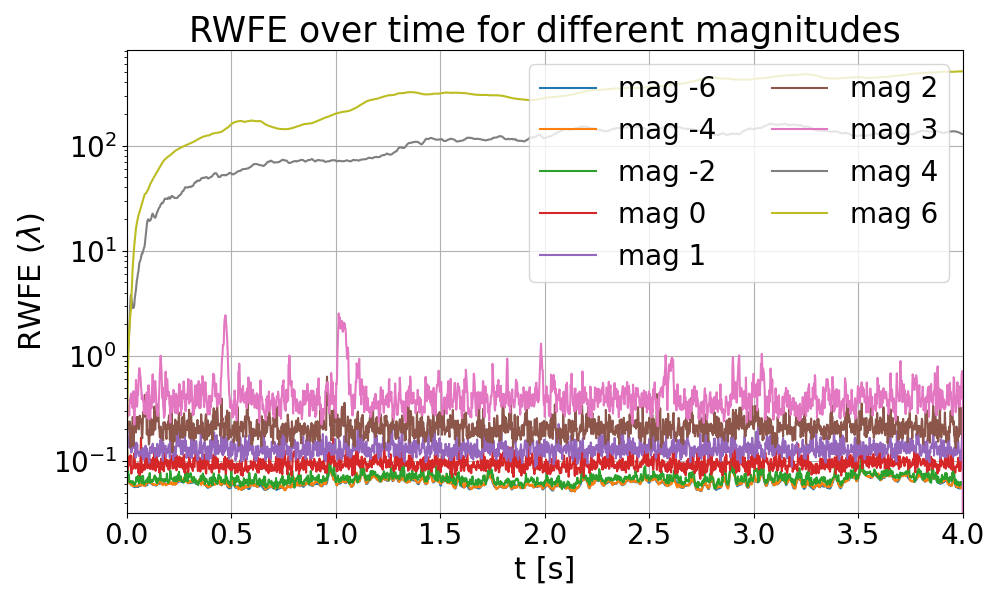

In [ ]:
rwfe = np.zeros((len(magnitudes), 2743))
for i, mag in enumerate(magnitudes):
    with h5py.File(f"mag_swipe/magnitude_{mag}/ao_rwfe_1.h5") as temp:
        rwfe[i] = temp[list(temp.keys())[0]][()]

ticks = np.arange(0, exposureTime + 1, 250)

plt.close(0)
plt.figure(0,figsize=(10, 6))
for i, mag in enumerate(magnitudes):
    plt.semilogy(rwfe[i], label=f"mag {mag}")
plt.xlabel("t [s]", fontsize=MEDIUM_SIZE)
plt.ylabel(r"RWFE ($\lambda$)", fontsize=MEDIUM_SIZE)
plt.title("RWFE over time for different magnitudes", fontsize=BIGGER_SIZE)
plt.xlim(0, exposureTime)
# plt.xticks(fontsize=SMALL_SIZE)
plt.yticks(fontsize=SMALL_SIZE)
plt.grid()
plt.legend(ncol=2, loc="upper right", fontsize=SMALL_SIZE)
plt.tight_layout()
plt.savefig(os.path.join(output_dir, "rwfe_over_time.png"), dpi=300)


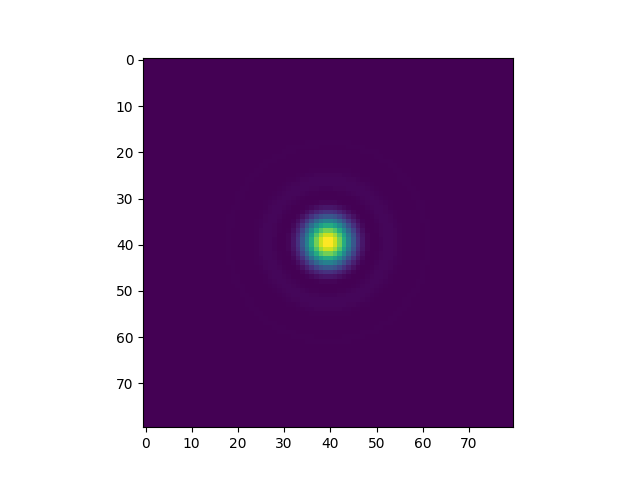

In [49]:
ipsf_difflim = np.zeros((len(magnitudes), *psf_shape))
for i, mag in enumerate(magnitudes):
    with h5py.File(f"mag_swipe/magnitude_{mag}/ipsf_difflim.h5") as temp:
        ipsf_difflim[i] = temp[list(temp.keys())[0]][()]

plt.close(0)
plt.figure(0)
plt.imshow(ipsf_difflim[1,:,:])

(9, 2000, 80, 80)


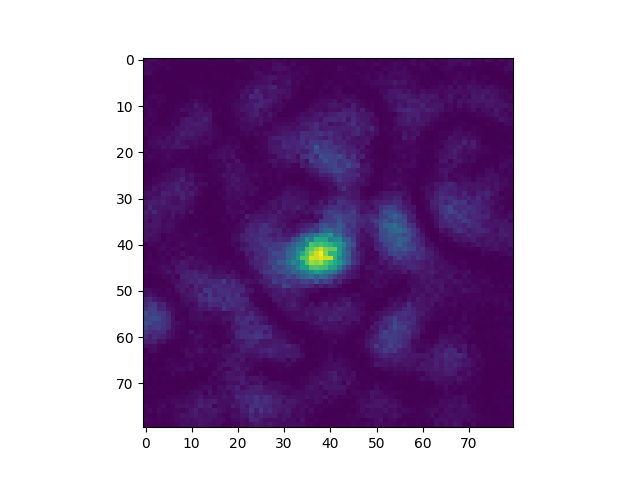

In [ ]:
ipsfs = np.zeros((len(magnitudes), exposureTime, *psf_shape))
print(ipsfs.shape)
for i, mag in enumerate(magnitudes):
    with h5py.File(f"mag_swipe/magnitude_{mag}/ao_ipsf_1.h5") as temp:
        ipsfs[i] = temp[list(temp.keys())[0]][startDelay:n]

plt.close(0)
plt.figure(0)
plt.imshow(ipsfs[6,150,:,:])

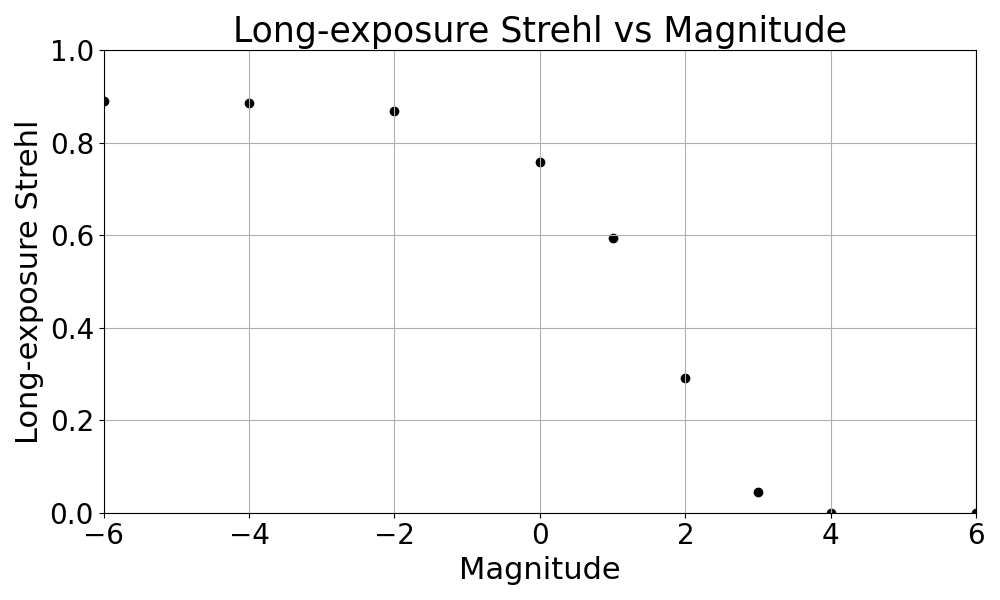

In [ ]:
long = np.zeros((len(magnitudes), *psf_shape))
for i, mag in enumerate(magnitudes):
    long[i] = np.sum(ipsfs[i], axis=0)

diff_lim = ipsf_difflim*exposureTime

longStrehl = np.zeros(len(magnitudes))
for i in range(len(magnitudes)):
    longStrehl[i] = long[i].max()/diff_lim[i].max()
    # print(f"longStrehl for mag {magnitudes[i]}: {longStrehl[i]}")

plt.close(0)
plt.figure(0, figsize=(10, 6))
plt.scatter(magnitudes, longStrehl, marker="o", color="k")
plt.xlabel("Magnitude", fontsize=MEDIUM_SIZE)
plt.ylabel("Long-exposure Strehl", fontsize=MEDIUM_SIZE)
plt.grid()
plt.ylim(0, 1)
plt.xlim(magnitudes[0], magnitudes[-1])
plt.title("Long-exposure Strehl vs Magnitude", fontsize=BIGGER_SIZE)
plt.xticks(fontsize=SMALL_SIZE)
plt.yticks(fontsize=SMALL_SIZE)
plt.tight_layout()
plt.savefig(os.path.join(output_dir, "long_exposure_strehl.png"), dpi=300)

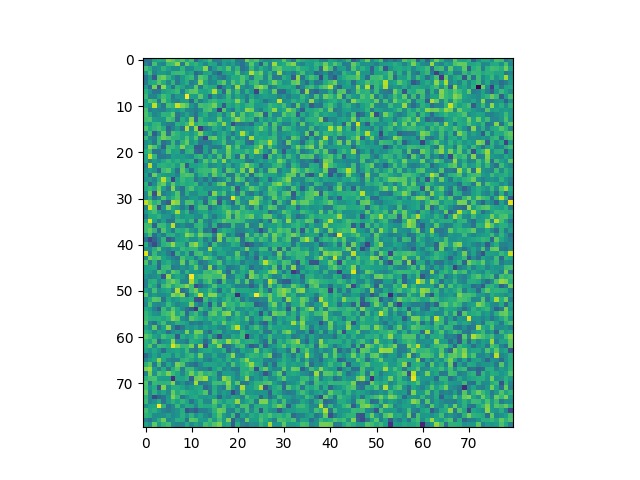